# Multi-Class Benchmark Classification Pipeline — Iris
## Comprehensive Exploratory Analysis, Classification, Evaluation, and Interpretation

This notebook expands the original assignment using the supplied Iris CSV from `data/iris.csv`. It retains the benchmark workflow and integrates the requested advanced plots into one coherent, reproducible analysis.

### Project objectives
- Validate and understand the dataset and target distribution.
- Explore feature distributions, pairwise relationships, and correlations.
- Create a stratified 80/20 train/test split.
- Train Logistic Regression and Decision Tree classifiers using Scikit-learn pipelines.
- Evaluate both models with accuracy, precision, recall, F1-score, confusion matrices, ROC/AUC, and precision-recall analysis.
- Interpret model structure through PCA, feature importance, coefficients, learning curves, and prediction confidence.
- Compare models and inspect individual test predictions.

### Tools and Tech-stacks
Python, Pandas, Scikit-learn, Seaborn, and Matplotlib. NumPy is used for numerical grid operations and as a dependency of the scientific Python stack.

### Dataset
The supplied CSV contains four numerical predictors (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`) and the categorical target `species`.

### Methodological safeguards
The train/test split is stratified and reproducible. Scalers, PCA, and classifiers are fitted on training data only. ROC and precision-recall curves use predicted probabilities. Learning curves use stratified cross-validation only within the training partition. The test set remains reserved for final evaluation.

Each visualization is followed by a discussion of what it displays, how to interpret it, and what conclusions are justified. Correlation and feature importance are not treated as causal evidence.


## 1. Imports, configuration, and dataset loading

In [1]:
from pathlib import Path

import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_curve,
    auc,
)
from sklearn.model_selection import (
    StratifiedKFold,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "iris.csv").exists():
    PROJECT_ROOT = Path("..")
DATA_PATH = PROJECT_ROOT / "data" / "iris.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
TARGET = "species"

data = pd.read_csv(DATA_PATH)
required_columns = FEATURES + [TARGET]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(f"Missing required columns in CSV: {missing_columns}")

data = data[required_columns].copy()
for column in FEATURES:
    data[column] = pd.to_numeric(data[column], errors="raise")
if data.isna().any().any():
    raise ValueError(f"Missing values found:\n{data.isna().sum()}")

data[TARGET] = data[TARGET].astype(str)
class_labels = sorted(data[TARGET].unique())
print(f"Dataset shape: {data.shape}")
print(f"Classes: {class_labels}")
display(data.head())


Dataset shape: (150, 5)
Classes: ['setosa', 'versicolor', 'virginica']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Target-class frequency

Before modeling, inspect how many examples belong to each species. Class balance affects how metrics should be interpreted and whether accuracy alone is a sufficient summary.

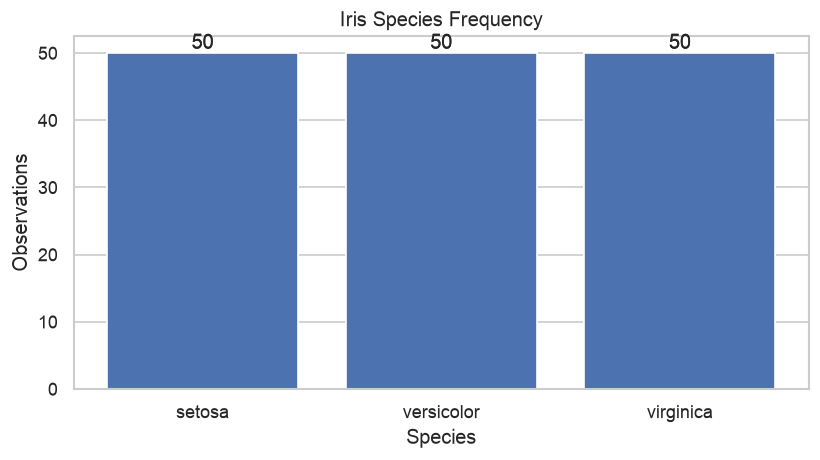

,observations
species,
setosa,50
versicolor,50
virginica,50


In [5]:
class_counts = data[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=data, x=TARGET, hue=TARGET, legend=False)
ax.bar(class_counts.index, class_counts.values)
ax.set_title("Iris Species Frequency")
ax.set_xlabel("Species")
ax.set_ylabel("Observations")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "00_class_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(class_counts.rename("observations").to_frame())

**Interpretation.** The supplied dataset contains 150 records, with 50 observations for each of setosa, versicolor, and virginica. The classes are balanced. Stratification therefore preserves approximately equal class representation in the 80/20 split. Accuracy is meaningful in this dataset, while macro-averaged metrics are also reported to weight all species equally.

## 2. Exploratory data analysis

### 2.1 Correlation heatmap

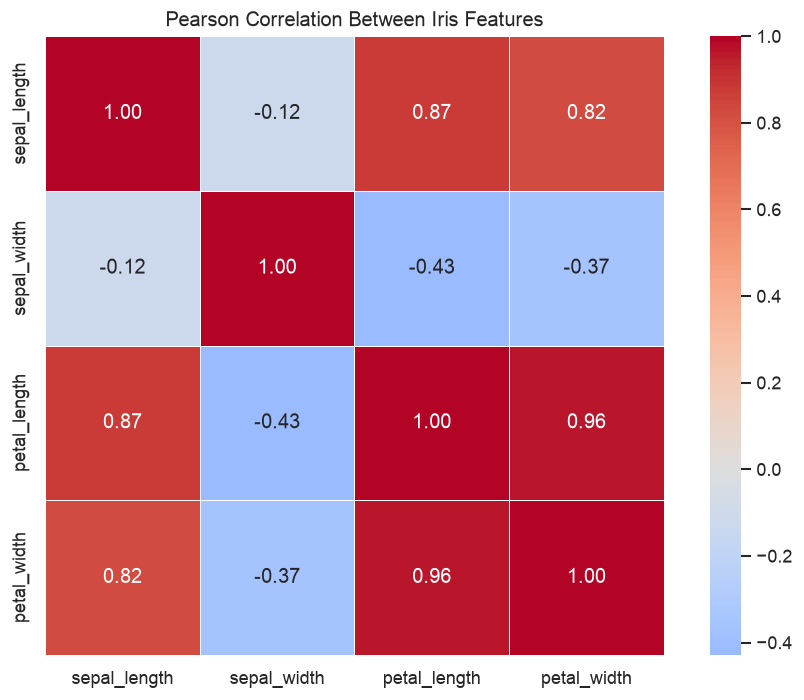

In [6]:
correlation = data[FEATURES].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, linewidths=0.5, ax=ax
)
ax.set_title("Pearson Correlation Between Iris Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_correlation_heatmap.png", bbox_inches="tight")
plt.show()


**Interpretation.** Correlations close to +1 indicate strong positive linear association; values near −1 indicate negative association; values near 0 indicate weak linear association. Petal length and petal width are strongly positively associated in this dataset. Correlation helps reveal shared information among predictors but does not establish causality.

### 2.2 Feature boxplots by species

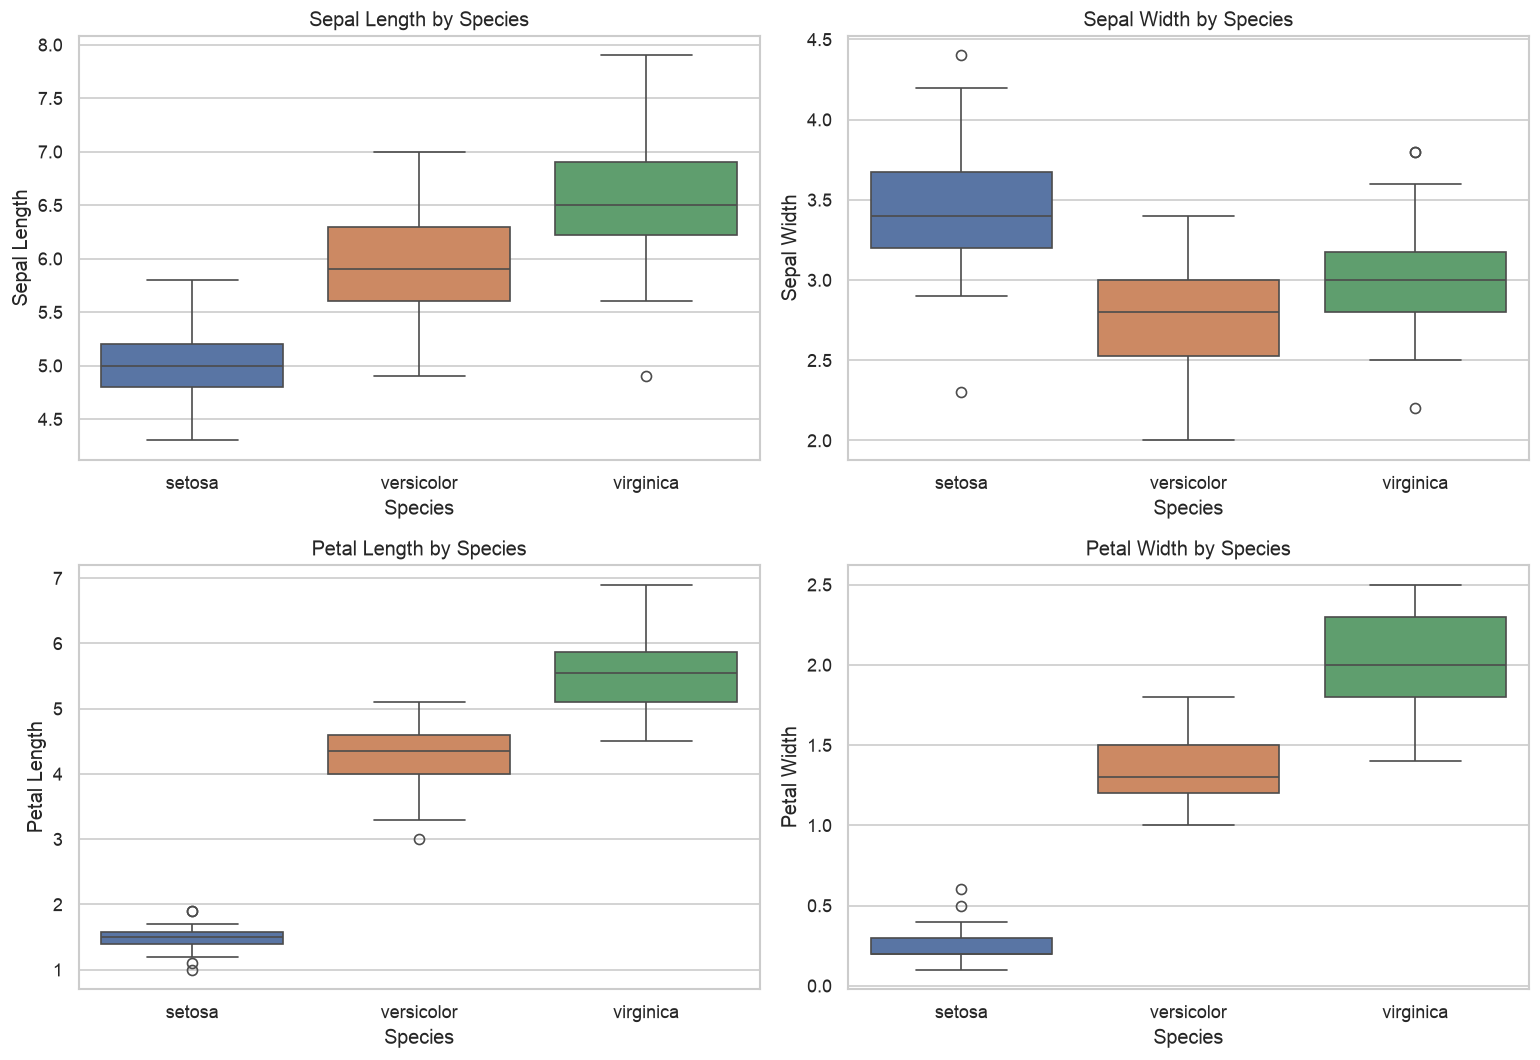

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(FEATURES, axes.flat):
    sns.boxplot(data=data, x=TARGET, y=feature, hue=TARGET, legend=False, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature.replace("_", " ").title())
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_feature_boxplots.png", bbox_inches="tight")
plt.show()

**Interpretation.** The center line is the median, the box spans the interquartile range, and whiskers summarize the spread under the boxplot convention. Potential points beyond whiskers are not automatically errors. Petal measurements show clearer species-level separation than sepal measurements; versicolor and virginica retain some overlap.

### 2.3 Violin plots

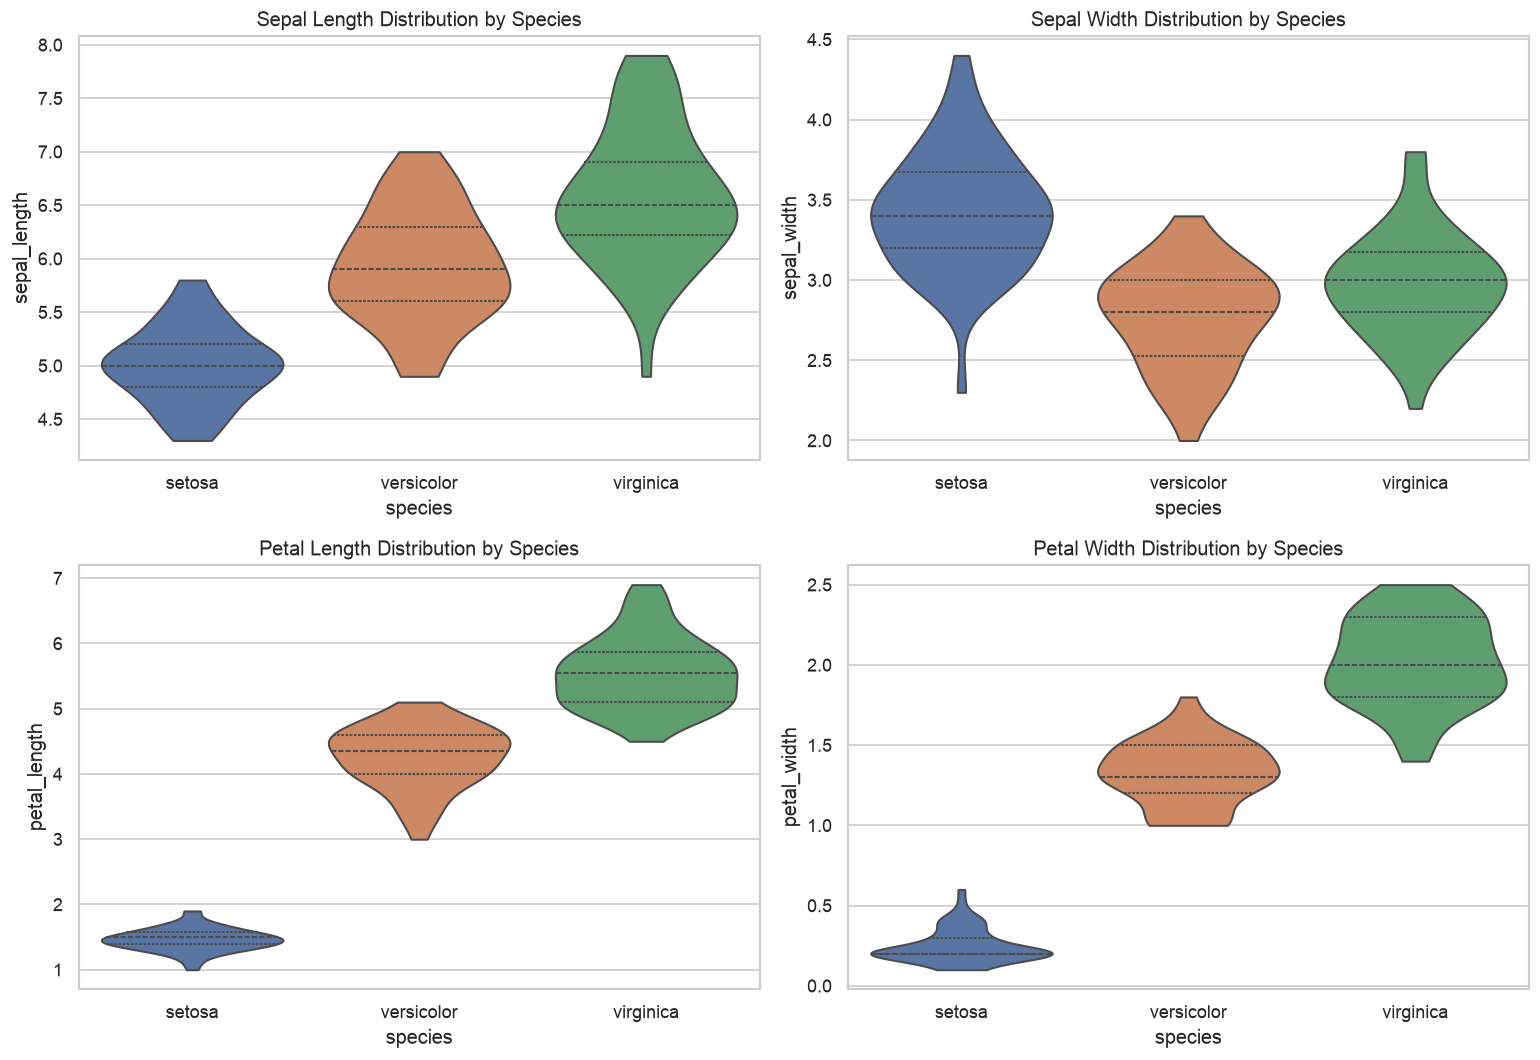

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(FEATURES, axes.flat):
    sns.violinplot(
        data=data, x=TARGET, y=feature, hue=TARGET,
        legend=False, inner="quartile", cut=0, ax=ax
    )
    ax.set_title(f"{feature.replace('_', ' ').title()} Distribution by Species")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_violin_plots.png", bbox_inches="tight")
plt.show()

**Interpretation.** Violin width represents estimated observation density; the inner quartile marks summarize central spread. These plots show distribution shape as well as central tendency. Petal features exhibit more distinct species-specific distributions. Density estimates are approximate, particularly with only 50 observations per species.

### 2.4 Feature histograms

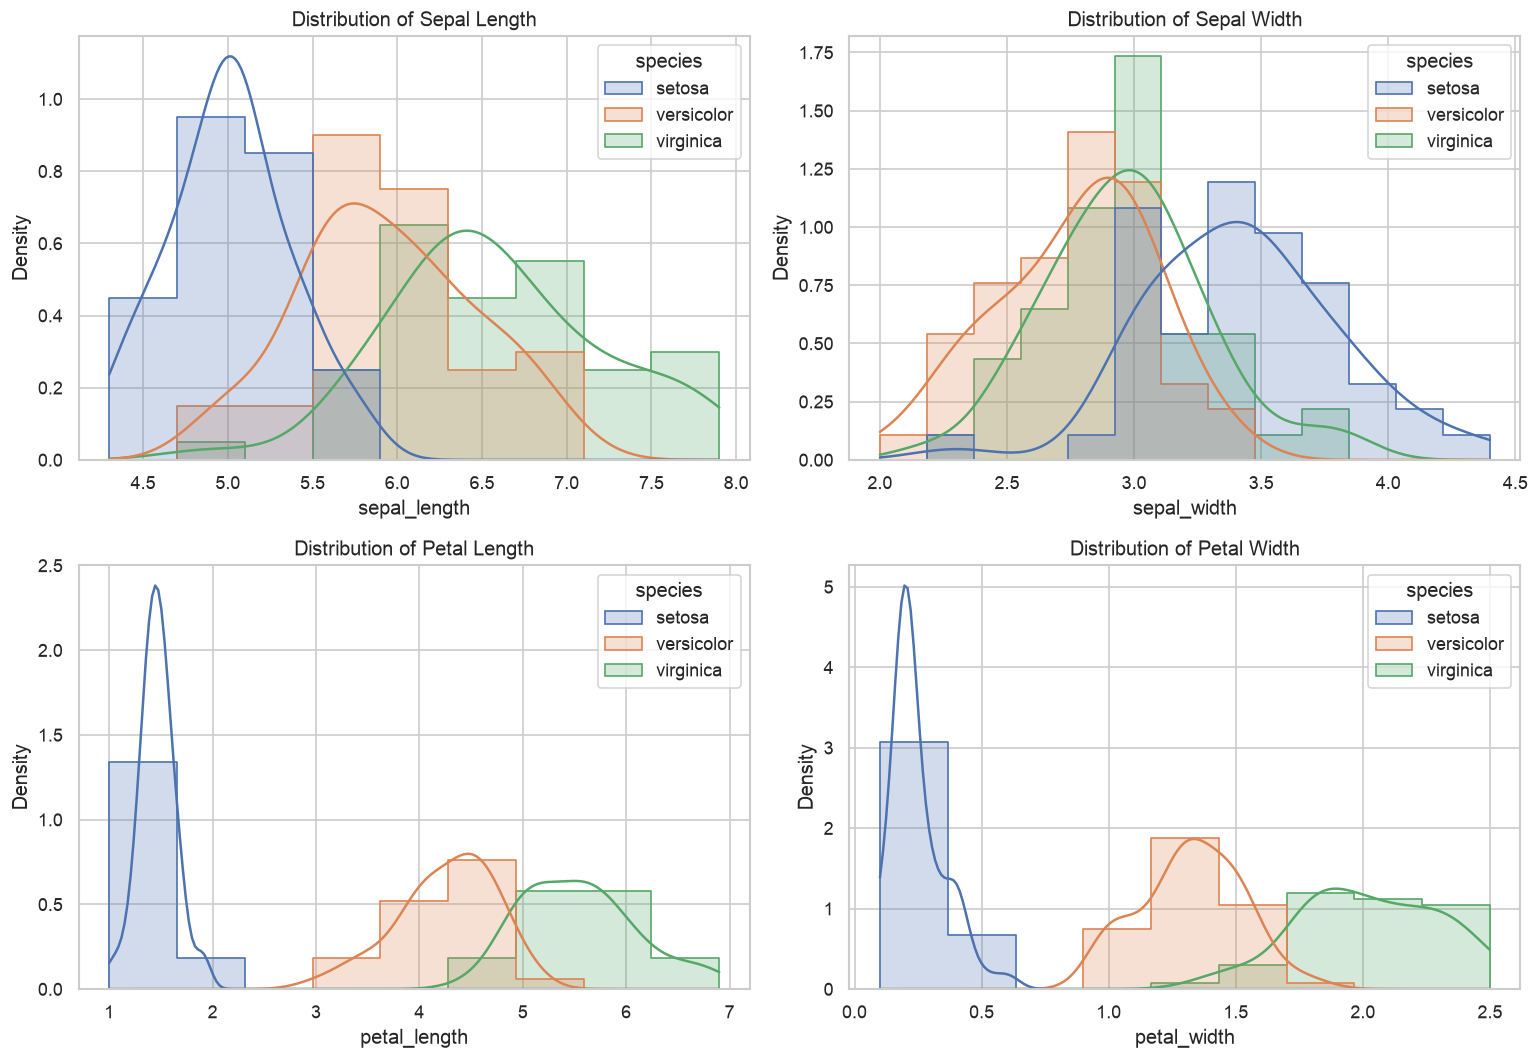

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(FEATURES, axes.flat):
    sns.histplot(
        data=data, x=feature, hue=TARGET, kde=True,
        element="step", stat="density", common_norm=False, ax=ax
    )
    ax.set_title(f"Distribution of {feature.replace('_', ' ').title()}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_feature_histograms.png", bbox_inches="tight")
plt.show()

**Interpretation.** Histograms show where measurements are concentrated, while KDE curves provide a smoothed density estimate. Species overlays expose overlapping and separated ranges. Petal measurements generally provide more visible class separation than sepal measurements. Histograms describe the data; they do not measure model accuracy.

### 2.5 Pairwise feature relationships

The pairplot shows each numerical feature against every other feature. Diagonal panels show individual distributions; off-diagonal panels show pairwise relationships, with color representing species.

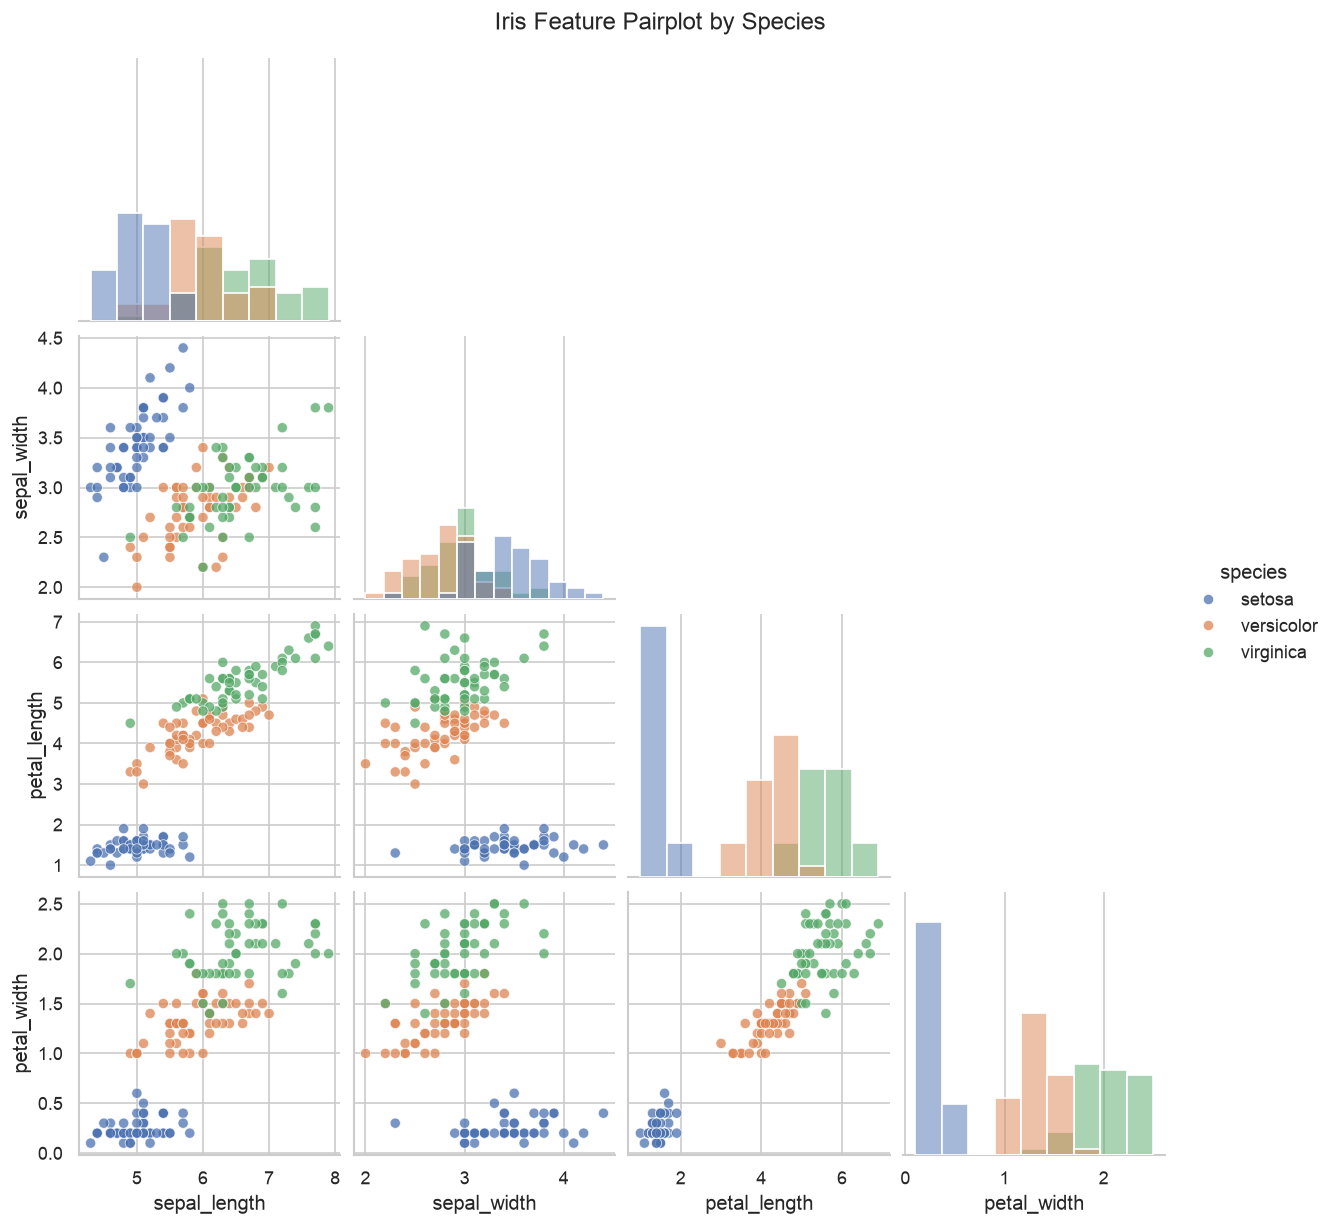

In [10]:
pair_grid = sns.pairplot(
    data, vars=FEATURES, hue=TARGET, diag_kind="hist", corner=True,
    plot_kws={"alpha": 0.75, "s": 38},
)
pair_grid.fig.suptitle("Iris Feature Pairplot by Species", y=1.02)
pair_grid.savefig(OUTPUT_DIR / "00b_pairplot.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(pair_grid.fig)


**Interpretation.** Petal length and petal width tend to distinguish the species more clearly than sepal measurements. Setosa forms a particularly distinct cluster, while versicolor and virginica overlap more. The pairplot motivates using all four predictors and cautions against assuming that one two-feature view fully describes the classification problem. Associations in this plot are descriptive, not causal.

## 3. Stratified train/test split and model training

In [11]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
display(pd.DataFrame({
    "train_count": y_train.value_counts().sort_index(),
    "test_count": y_test.value_counts().sort_index(),
}))

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]),
}

for model in models.values():
    model.fit(X_train, y_train)

predictions = {name: model.predict(X_test) for name, model in models.items()}
probabilities = {name: model.predict_proba(X_test) for name, model in models.items()}


Train rows: 120 | Test rows: 30


,train_count,test_count
species,,
setosa,40,10
versicolor,40,10
virginica,40,10


## 4. PCA visualization

PCA is fitted on standardized **training features only**. The held-out test set is transformed with the same fitted scaler and PCA model. The plot therefore shows test observations in a coordinate system learned without using test data.

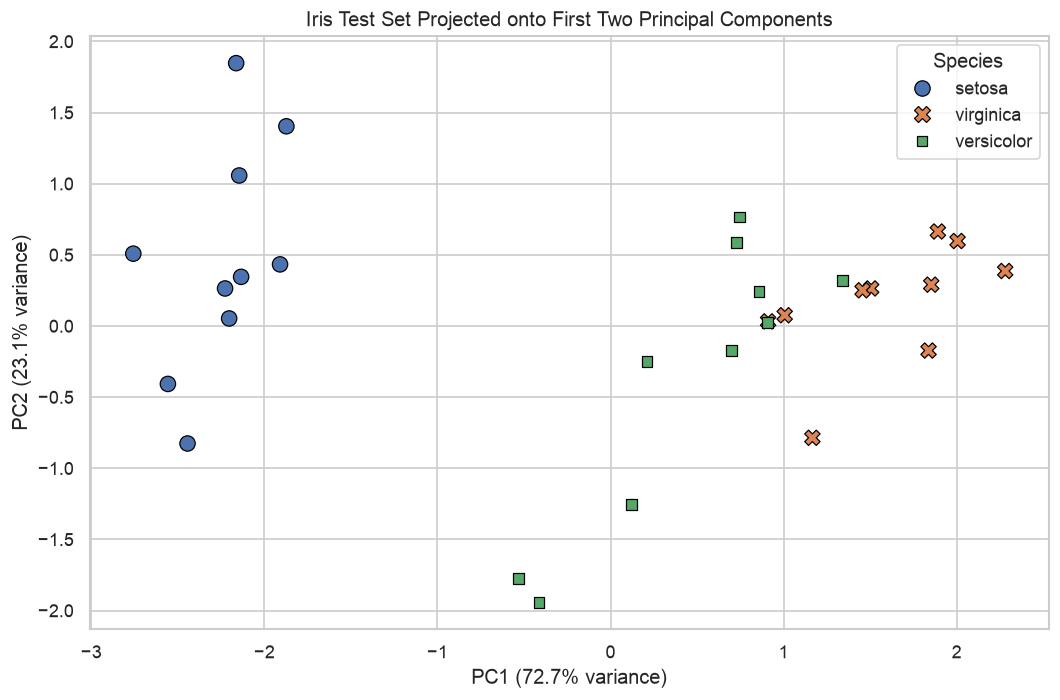

Explained variance ratio: [0.72677234 0.23066667]
Total variance explained by two components: 0.9574390106545367


In [12]:
pca_scaler = StandardScaler()
X_train_scaled = pca_scaler.fit_transform(X_train)
X_test_scaled = pca_scaler.transform(X_test)

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_test = pd.DataFrame(X_test_pca, columns=["PC1", "PC2"])
pca_test[TARGET] = y_test.to_numpy()

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=pca_test, x="PC1", y="PC2", hue=TARGET,
    style=TARGET, s=85, edgecolor="black", ax=ax
)
ax.set_title("Iris Test Set Projected onto First Two Principal Components")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.legend(title="Species")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_pca_visualization.png", bbox_inches="tight")
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained by two components:", pca.explained_variance_ratio_.sum())


**Interpretation.** PC1 and PC2 are weighted combinations of standardized features. The axis labels report the fraction of training-set variance explained by each component, and the printed sum reports the total represented in two dimensions. Species separation in this unsupervised projection suggests structure in the predictors, but PCA maximizes variance rather than class separation. The test data is transformed using the scaler and PCA fitted on training data only.

## Decision-boundary slices

The classifiers use all four features, so their complete decision functions are four-dimensional. For visualization, petal length and petal width vary across a mesh while sepal length and sepal width are held at their training medians. Predictions still come from the fitted four-feature pipelines.

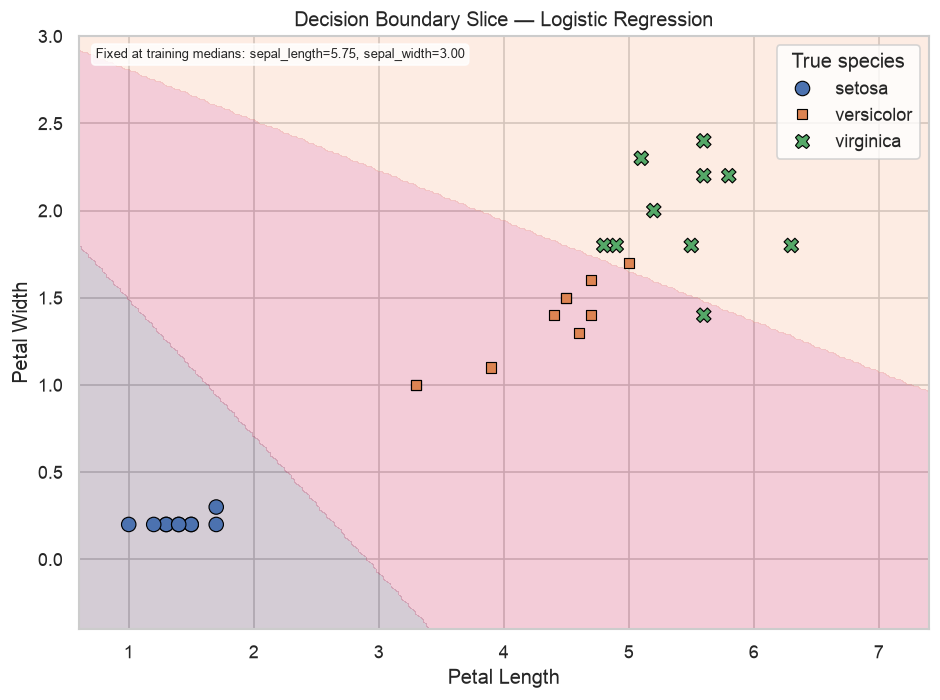

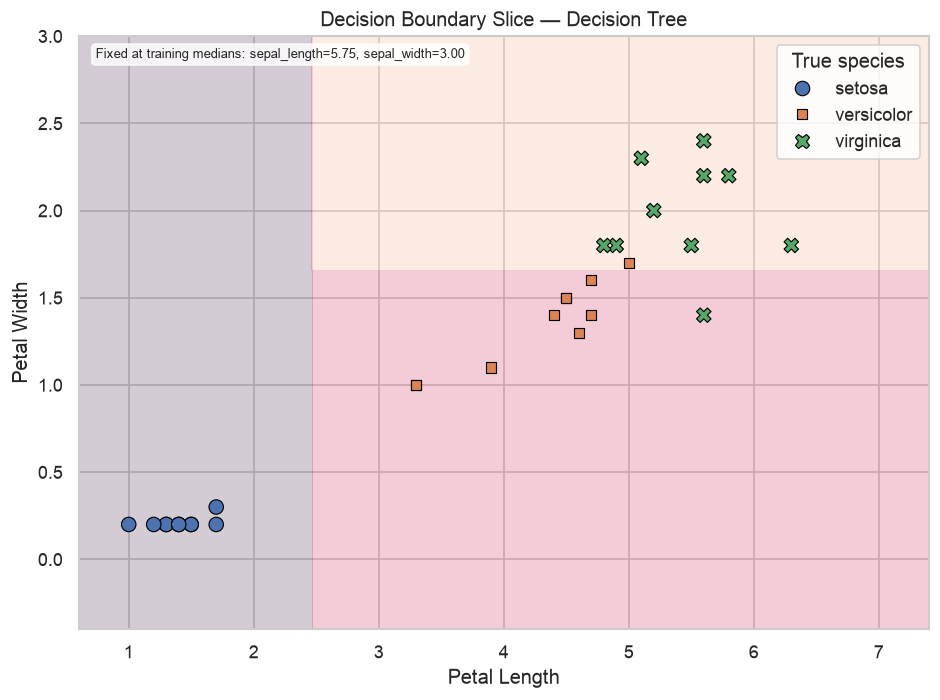

In [13]:
boundary_features = ["petal_length", "petal_width"]
x_feature, y_feature = boundary_features
x_min, x_max = X_train[x_feature].min() - 0.5, X_train[x_feature].max() + 0.5
y_min, y_max = X_train[y_feature].min() - 0.5, X_train[y_feature].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 240), np.linspace(y_min, y_max, 240))
boundary_grid = pd.DataFrame({
    feature: np.repeat(X_train[feature].median(), xx.size) for feature in FEATURES
})
boundary_grid[x_feature] = xx.ravel()
boundary_grid[y_feature] = yy.ravel()
class_to_number = {label: index for index, label in enumerate(class_labels)}

for model_name, model in models.items():
    region = pd.Series(model.predict(boundary_grid)).map(class_to_number).to_numpy().reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.contourf(xx, yy, region, alpha=0.22, levels=len(class_labels)-1)
    test_plot = X_test[[x_feature, y_feature]].copy()
    test_plot[TARGET] = y_test.to_numpy()
    sns.scatterplot(data=test_plot, x=x_feature, y=y_feature, hue=TARGET,
                    hue_order=class_labels, style=TARGET, s=75,
                    edgecolor="black", ax=ax)
    fixed = ", ".join(
        f"{f}={X_train[f].median():.2f}" for f in FEATURES if f not in boundary_features
    )
    ax.set_title(f"Decision Boundary Slice — {model_name}")
    ax.set_xlabel(x_feature.replace("_", " ").title())
    ax.set_ylabel(y_feature.replace("_", " ").title())
    ax.text(0.02, 0.98, f"Fixed at training medians: {fixed}",
            transform=ax.transAxes, va="top", fontsize=8,
            bbox={"boxstyle":"round", "facecolor":"white", "alpha":0.8})
    ax.legend(title="True species")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"decision_boundary_{model_name.lower().replace(' ', '_')}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Interpretation.** Shaded areas indicate predicted classes in this two-feature slice; points show held-out observations colored by their actual species. Points falling in a differently colored region may correspond to a potential error in this slice. Because the other two predictors are fixed, this is not the complete four-dimensional decision boundary and is not a new model trained on only two features.

## 5. Feature importance and Logistic Regression coefficients

The Decision Tree exposes impurity-based `feature_importances_`. Logistic Regression coefficients are plotted by class; their signs indicate the direction of each feature's contribution to that class's decision score. Coefficient magnitudes are on standardized feature scales.

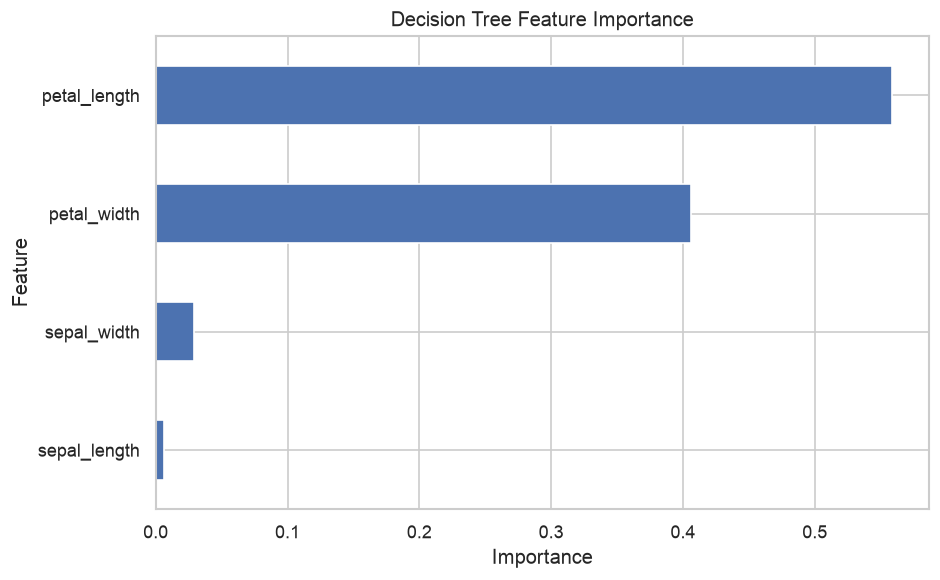

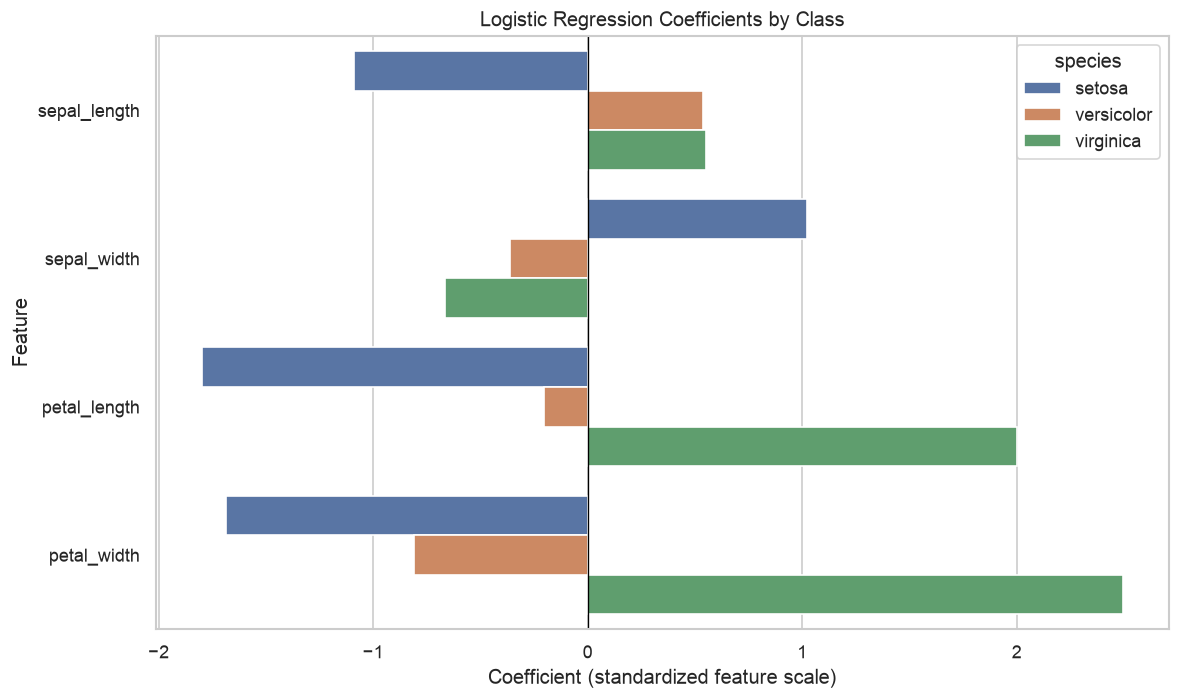

In [14]:
tree_model = models["Decision Tree"].named_steps["classifier"]
tree_importance = pd.Series(
    tree_model.feature_importances_, index=FEATURES
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
tree_importance.plot(kind="barh", ax=ax)
ax.set_title("Decision Tree Feature Importance")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06a_decision_tree_feature_importance.png", bbox_inches="tight")
plt.show()

logistic_model = models["Logistic Regression"].named_steps["classifier"]
coefficient_frame = pd.DataFrame(
    logistic_model.coef_, index=logistic_model.classes_, columns=FEATURES
)
coefficient_long = (
    coefficient_frame.rename_axis("species")
    .reset_index()
    .melt(id_vars="species", var_name="feature", value_name="coefficient")
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=coefficient_long, x="coefficient", y="feature",
    hue="species", ax=ax
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression Coefficients by Class")
ax.set_xlabel("Coefficient (standardized feature scale)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06b_logistic_regression_coefficients.png", bbox_inches="tight")
plt.show()


**Interpretation.** Each Logistic Regression bar is a class-specific coefficient on standardized inputs. A positive coefficient increases that class's decision score as the feature increases, holding other features fixed; a negative coefficient decreases it. Coefficients are not probabilities and should be interpreted jointly, especially because some predictors are correlated.

**Interpretation.** Larger Decision Tree importance values mean a feature contributed more to impurity reduction in this fitted tree. The importances sum to one. This is model-specific and can be influenced by tree split choices; it is not a causal effect or a universal ranking of feature usefulness.

## 6. Multi-class ROC curves and AUC

The multi-class ROC analysis uses a one-vs-rest approach. Each class is treated as positive while the remaining classes are treated as negative. Curves use predicted probabilities, not hard class predictions.

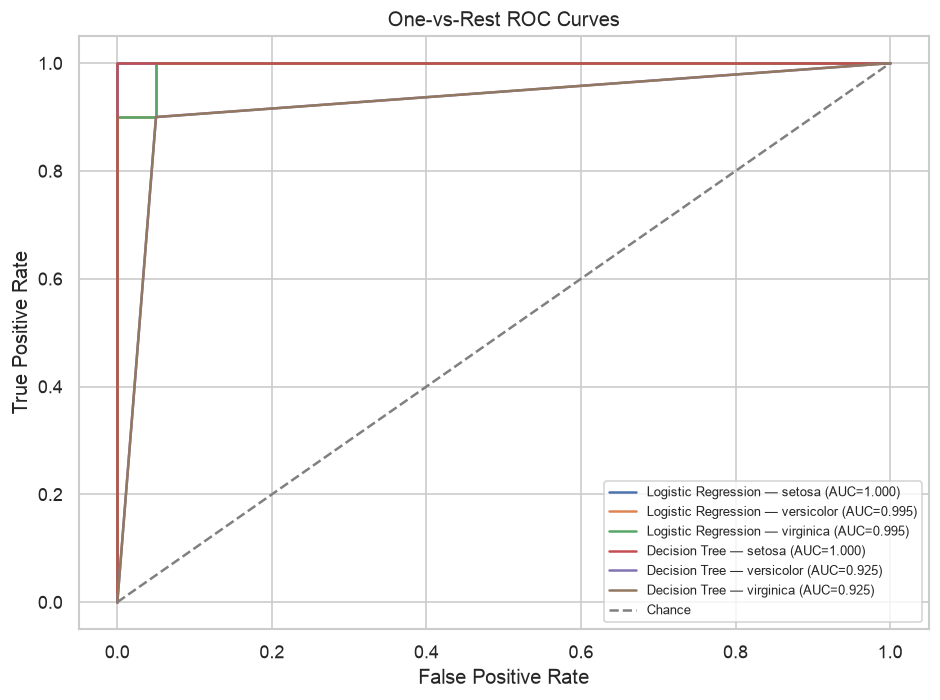

model,Decision Tree,Logistic Regression
class,,
setosa,1.000,1.000
versicolor,0.925,0.995
virginica,0.925,0.995


In [15]:
y_test_binary = pd.DataFrame(
    label_binarize(y_test, classes=class_labels),
    columns=class_labels, index=y_test.index
)

fig, ax = plt.subplots(figsize=(8, 6))
roc_rows = []
for model_name, model_probabilities in probabilities.items():
    for class_index, class_name in enumerate(class_labels):
        fpr, tpr, _ = roc_curve(y_test_binary.iloc[:, class_index], model_probabilities[:, class_index])
        class_auc = auc(fpr, tpr)
        roc_rows.append({"model": model_name, "class": class_name, "auc": class_auc})
        ax.plot(fpr, tpr, label=f"{model_name} — {class_name} (AUC={class_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("One-vs-Rest ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_multiclass_roc_auc.png", bbox_inches="tight")
plt.show()

roc_auc_table = pd.DataFrame(roc_rows)
display(roc_auc_table.pivot(index="class", columns="model", values="auc").round(4))

**Interpretation.** ROC curves plot true-positive rate against false-positive rate across thresholds. AUC summarizes ranking discrimination: 1.0 indicates perfect ranking and 0.5 is chance-level. The one-vs-rest approach evaluates each species against the other two. With only 10 test observations per class, these curves are stepwise and AUC estimates are sensitive to the split.

## 7. Multi-class precision-recall curves

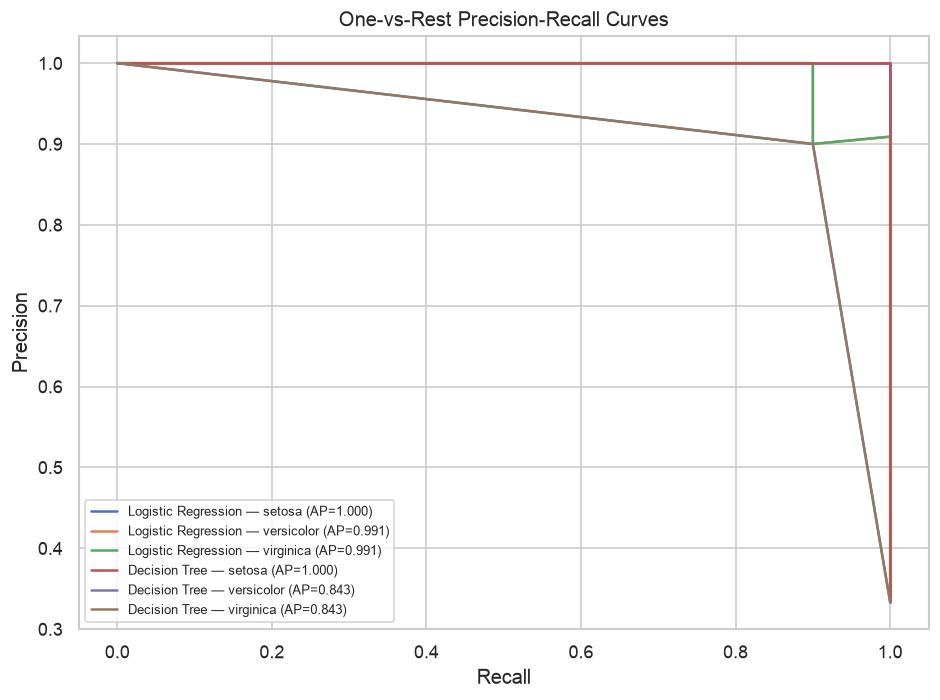

model,Decision Tree,Logistic Regression
class,,
setosa,1.0000,1.0000
versicolor,0.8433,0.9909
virginica,0.8433,0.9909


In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
pr_rows = []
for model_name, model_probabilities in probabilities.items():
    for class_index, class_name in enumerate(class_labels):
        precision, recall, _ = precision_recall_curve(
            y_test_binary.iloc[:, class_index], model_probabilities[:, class_index]
        )
        ap = average_precision_score(
            y_test_binary.iloc[:, class_index], model_probabilities[:, class_index]
        )
        pr_rows.append({"model": model_name, "class": class_name, "average_precision": ap})
        ax.plot(recall, precision, label=f"{model_name} — {class_name} (AP={ap:.3f})")

ax.set_title("One-vs-Rest Precision-Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_precision_recall_curves.png", bbox_inches="tight")
plt.show()

ap_table = pd.DataFrame(pr_rows)
display(ap_table.pivot(index="class", columns="model", values="average_precision").round(4))

**Interpretation.** Precision-recall curves show the trade-off between the fraction of positive predictions that are correct (precision) and the fraction of actual positives recovered (recall). Average precision summarizes the curve. These class-wise views are useful complements to ROC; the limited test-set size makes their curves coarse.

## 8. Learning curves

Learning curves use stratified 5-fold cross-validation on the training partition only. The held-out test set is not used to select model parameters or estimate cross-validation scores.

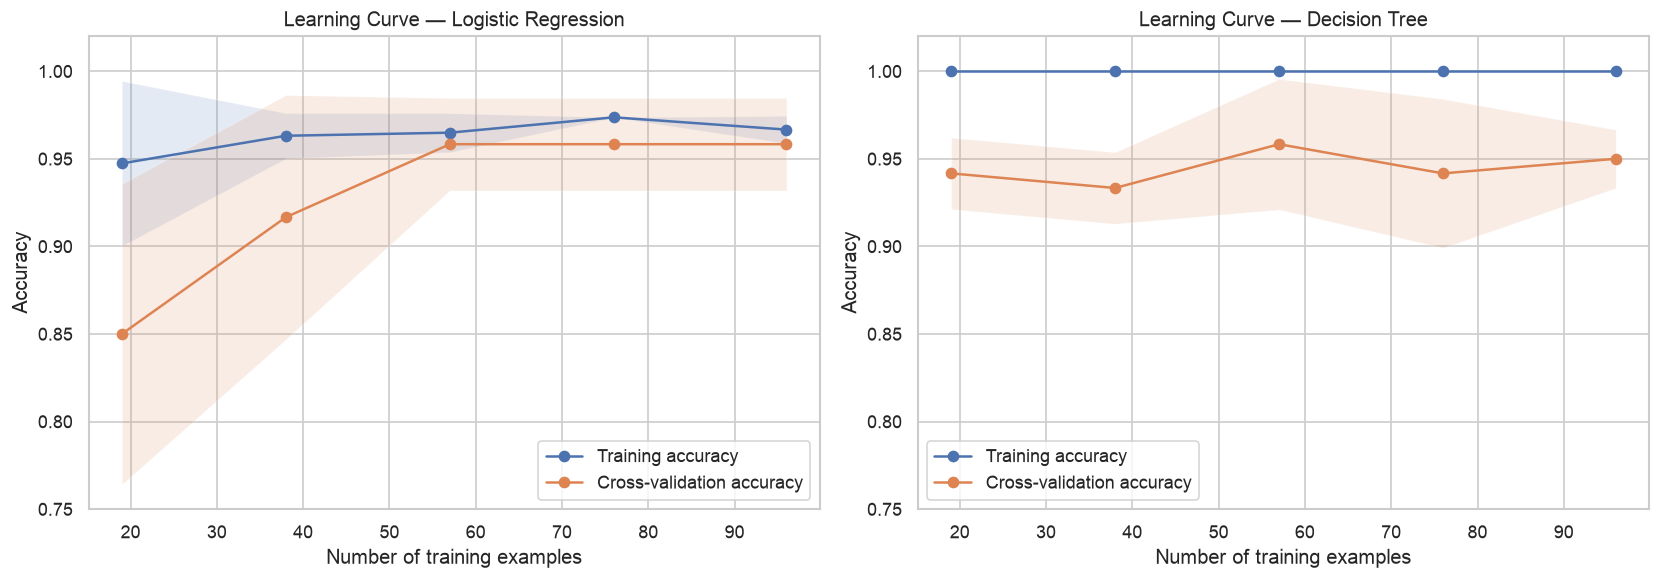

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
learning_curve_rows = []

for (model_name, estimator), ax in zip(models.items(), axes):
    sizes, train_scores, validation_scores = learning_curve(
        estimator,
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="accuracy",
        n_jobs=None,
        shuffle=True,
        random_state=42,
    )
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    validation_mean = validation_scores.mean(axis=1)
    validation_std = validation_scores.std(axis=1)

    ax.plot(sizes, train_mean, marker="o", label="Training accuracy")
    ax.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
    ax.plot(sizes, validation_mean, marker="o", label="Cross-validation accuracy")
    ax.fill_between(
        sizes, validation_mean - validation_std,
        validation_mean + validation_std, alpha=0.15
    )
    ax.set_title(f"Learning Curve — {model_name}")
    ax.set_xlabel("Number of training examples")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.75, 1.02)
    ax.legend()
    for size, tr, val in zip(sizes, train_mean, validation_mean):
        learning_curve_rows.append({
            "model": model_name, "training_examples": size,
            "training_accuracy": tr, "cv_accuracy": val
        })

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_learning_curves.png", bbox_inches="tight")
plt.show()

**Interpretation.** Training accuracy measures fit on the fold's training subset; cross-validation accuracy estimates performance on held-out folds. A persistent gap suggests possible overfitting. Low values for both suggest underfitting. Improving validation scores as sample size increases may indicate that more training data would help. Shaded regions show fold variability. Only the training partition is used here.

## 9. Prediction confidence distribution

For each test observation, prediction confidence is defined as the maximum class probability from the fitted model. Correctness is determined by comparing the predicted label with the true label. Probabilities are model scores and should not automatically be interpreted as calibrated probabilities.

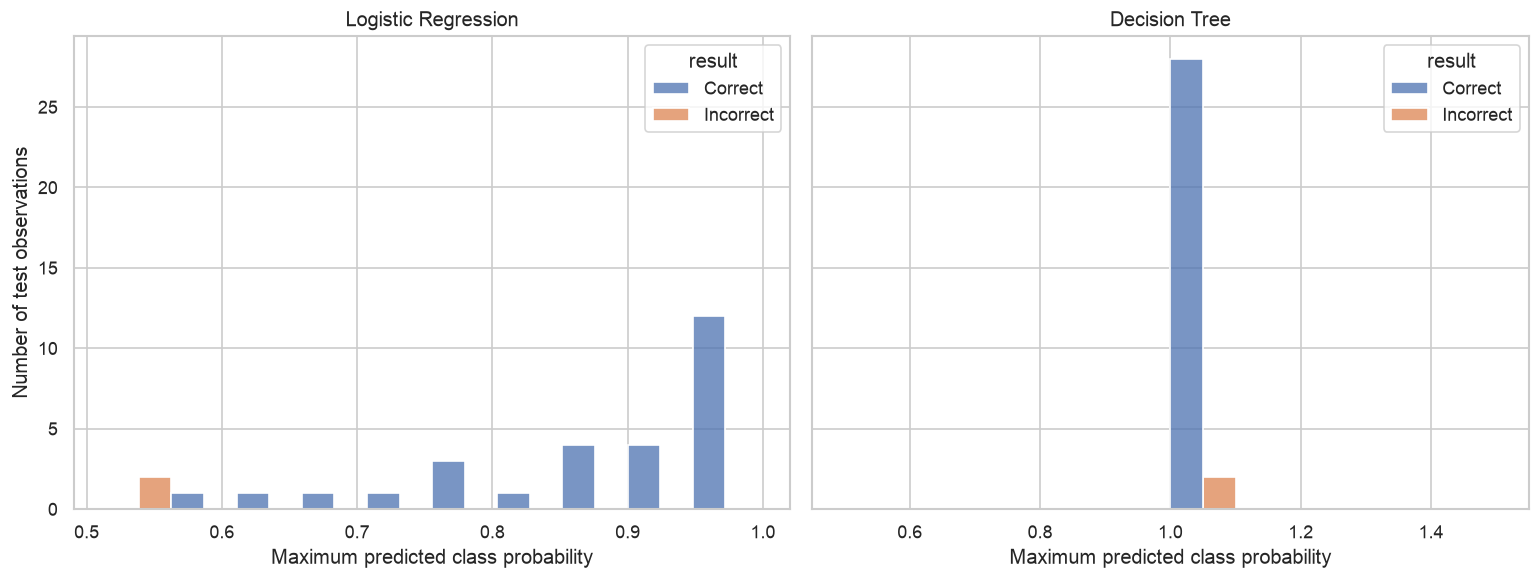

In [18]:
confidence_rows = []
for model_name, model_probabilities in probabilities.items():
    predicted = predictions[model_name]
    confidence = model_probabilities.max(axis=1)
    correct = predicted == y_test.to_numpy()
    confidence_rows.extend([
        {
            "model": model_name,
            "confidence": float(conf),
            "result": "Correct" if is_correct else "Incorrect",
        }
        for conf, is_correct in zip(confidence, correct)
    ])

confidence_data = pd.DataFrame(confidence_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for model_name, ax in zip(models.keys(), axes):
    subset = confidence_data[confidence_data["model"] == model_name]
    sns.histplot(
        data=subset, x="confidence", hue="result",
        bins=10, multiple="dodge", stat="count",
        common_norm=False, ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Maximum predicted class probability")
    ax.set_ylabel("Number of test observations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_prediction_confidence.png", bbox_inches="tight")
plt.show()

**Interpretation.** Confidence is the maximum predicted class probability for each test observation. Higher values indicate stronger model preference, not guaranteed correctness or calibration. Comparing correct and incorrect predictions can show whether errors tend to occur at lower confidence. Decision Tree probabilities may be coarse because they reflect class proportions in terminal leaves.

## 10. Model performance comparison

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333


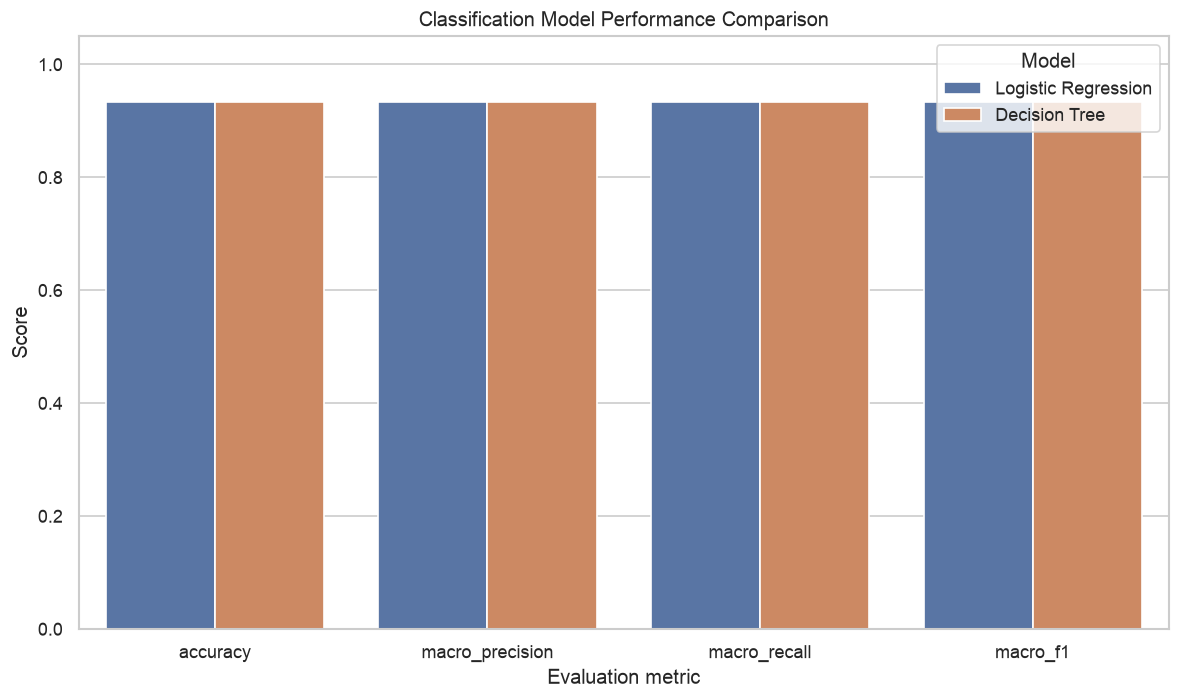

In [19]:
performance_rows = []
for model_name, predicted in predictions.items():
    macro = precision_recall_fscore_support(
        y_test, predicted, average="macro", zero_division=0
    )
    weighted = precision_recall_fscore_support(
        y_test, predicted, average="weighted", zero_division=0
    )
    performance_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, predicted),
        "macro_precision": macro[0],
        "macro_recall": macro[1],
        "macro_f1": macro[2],
        "weighted_precision": weighted[0],
        "weighted_recall": weighted[1],
        "weighted_f1": weighted[2],
    })

performance = pd.DataFrame(performance_rows)
display(performance.round(4))

plot_metrics = performance.melt(
    id_vars="model",
    value_vars=["accuracy", "macro_precision", "macro_recall", "macro_f1"],
    var_name="metric",
    value_name="score",
)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_metrics, x="metric", y="score", hue="model", ax=ax)
ax.set_title("Classification Model Performance Comparison")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "11_model_performance_comparison.png", bbox_inches="tight")
plt.show()

performance.to_csv(OUTPUT_DIR / "advanced_classification_metrics.csv", index=False)

**Interpretation.** This chart compares accuracy and macro precision, recall, and F1 on the same held-out test set. Macro averaging gives each species equal weight. Similar scores indicate comparable performance on this split, but do not prove statistical equivalence or guarantee the same ranking on new data.

## 11. Actual vs predicted classification

Each point represents a test observation. Points are grouped by true species and positioned by test-row index; marker shape indicates whether the prediction was correct. This makes individual errors visible without implying that class labels are continuous numerical measurements.

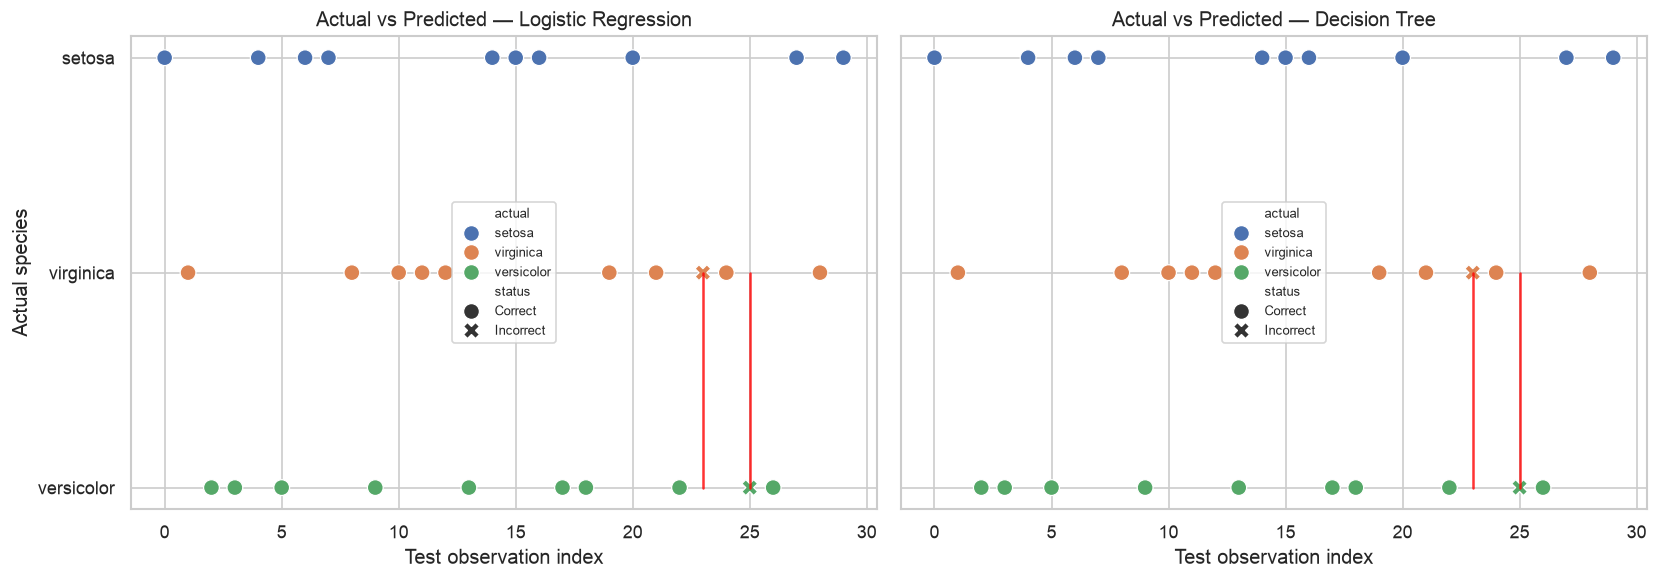

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
test_results = pd.DataFrame({
    "test_index": range(len(y_test)),
    "actual": y_test.to_numpy(),
})

for (model_name, predicted), ax in zip(predictions.items(), axes):
    result = test_results.copy()
    result["predicted"] = predicted
    result["status"] = [
        "Correct" if actual == predicted else "Incorrect"
        for actual, predicted in zip(result["actual"], result["predicted"])
    ]
    sns.scatterplot(
        data=result, x="test_index", y="actual",
        hue="actual", style="status", s=90, ax=ax
    )
    # Mark the predicted class with a short vertical segment to expose mismatches.
    for row in result.itertuples():
        if row.actual != row.predicted:
            ax.plot(
                [row.test_index, row.test_index],
                [row.actual, row.predicted],
                color="red", linewidth=1.5, alpha=0.8
            )
    ax.set_title(f"Actual vs Predicted — {model_name}")
    ax.set_xlabel("Test observation index")
    ax.set_ylabel("Actual species")
    ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "12_actual_vs_predicted.png", bbox_inches="tight")
plt.show()


**Interpretation.** Each marker represents a test observation, grouped by its actual species; marker style indicates whether its prediction was correct. Red connectors identify mismatches. The x-axis is test-row order and has no statistical meaning. This plot exposes individual errors, while confusion matrices summarize their class-to-class pattern.

## 12. Classification reports and confusion matrices

\nLogistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



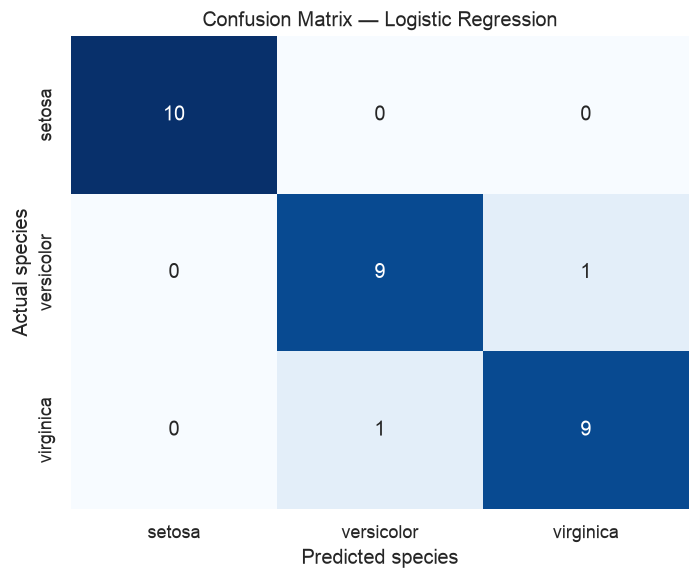

\nDecision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



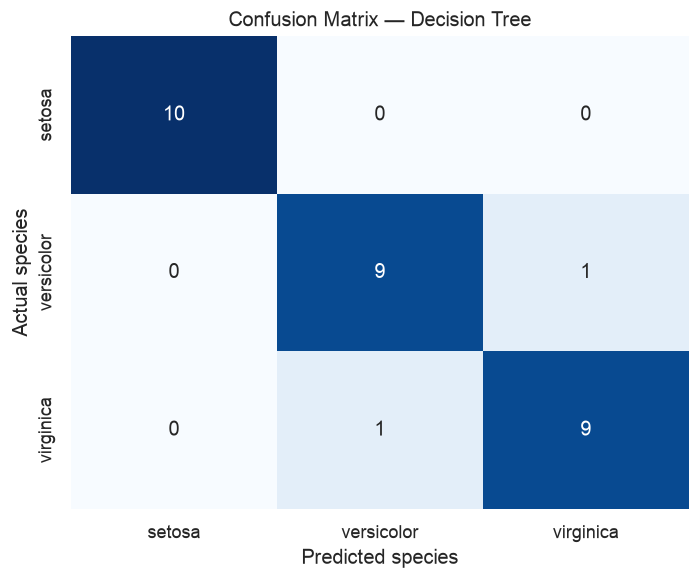

In [21]:
for model_name, predicted in predictions.items():
    print(f"\\n{model_name}")
    print(classification_report(y_test, predicted, labels=class_labels, zero_division=0))

    matrix = confusion_matrix(y_test, predicted, labels=class_labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_title(f"Confusion Matrix — {model_name}")
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")
    plt.tight_layout()
    filename = model_name.lower().replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"confusion_matrix_{filename}.png", bbox_inches="tight")
    plt.show()

**Interpretation.** Rows are actual classes and columns are predicted classes. Diagonal cells are correct predictions; off-diagonal cells show which species are confused. Since there are 10 test examples per class, each row sums to 10. Confusion matrices reveal the type of errors hidden by a single aggregate accuracy score.

## 13. Export summary tables and final interpretation

In [22]:
roc_auc_table.to_csv(OUTPUT_DIR / "multiclass_roc_auc.csv", index=False)
ap_table.to_csv(OUTPUT_DIR / "precision_recall_average_precision.csv", index=False)
confidence_data.to_csv(OUTPUT_DIR / "prediction_confidence.csv", index=False)

print("Advanced analysis complete.")
print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")
print("Compare models using test metrics, ROC/AUC, precision-recall, and learning curves.")
print("Use feature importance and coefficients as model-specific explanations, not causal effects.")

Advanced analysis complete.
Outputs saved to: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/iris-classification-pipeline/outputs
Compare models using test metrics, ROC/AUC, precision-recall, and learning curves.
Use feature importance and coefficients as model-specific explanations, not causal effects.


## Interpretation guidance

- **Correlation heatmap:** correlation indicates linear association, not causation.
- **Boxplots and violin plots:** compare spread, median, density, and potential outliers by species.
- **PCA:** principal components summarize variance; axes are combinations of original features.
- **Feature importance:** Decision Tree impurity importance can be biased toward features with more split opportunities.
- **Logistic coefficients:** signs and magnitudes are class-specific and apply to standardized inputs.
- **ROC/AUC and average precision:** computed one-vs-rest for each species using predicted probabilities. Small test sets make these estimates coarse.
- **Learning curves:** a gap between training and validation scores can indicate overfitting; low scores on both can indicate underfitting.
- **Prediction confidence:** maximum class probability is not necessarily calibrated.
- **Actual vs predicted:** mismatches reveal individual classification errors.

Because Iris is a small benchmark dataset, use these results to demonstrate a transparent workflow rather than claim production-level generalization.

## Overall conclusions, limitations, and reproducibility

### Overall conclusions
The exploratory plots indicate that petal length and petal width carry strong discriminatory information for the Iris species. Correlation and pairwise plots show relationships among predictors; boxplots, violins, and histograms reveal class-specific distributions. PCA provides a compact view of standardized feature variation. Model-specific plots then explain how the two classifiers use the available information and how well they perform on held-out observations.

### Evaluation cautions
The dataset is small and clean, and the held-out test set contains only 30 rows. A single split gives an uncertain estimate of generalization. Learning curves provide additional cross-validation context but do not replace evaluation on an external dataset. Predicted probabilities are not necessarily calibrated. Feature importance and coefficients are model explanations, not causal claims.

### Reproducibility
The train/test split and model random states are fixed. Run all cells from top to bottom. Figures and tables are saved under `outputs/`.